# 共享单车数据清洗与基础探索

**负责人：马文博**  
协作成员：陈宇涵（时间规律与需求预测）、康炜奕（空间分布与调度优化）。

本 Notebook 使用课程提供的 **2024 年 1 月骑行记录**，串联数据质量审查、清洗与基础特征、双子集导出、图1–3和分析解释。

运行前安装项目 `requirements.txt` 中的依赖，在 Jupyter 中选择 **Python (Pyclass)** 内核，然后执行“重启内核并运行全部单元格”。可从项目根目录或 `notebooks/` 目录启动。

运行会重新生成两份清洗 CSV、质量审查表、三张 300 DPI PNG 和两份基础探索统计表；原始 CSV 保持不变。清洗与计算逻辑直接复用 `src/`，不在 Notebook 中另设筛选规则。

## 1. 研究问题与运行环境

本部分回答四个问题：

1. 原始数据有哪些缺失、重复、时长和站点名称问题？
2. 为什么需要全量有效集和站点有效集两个子集？
3. 车型及会员类型对应的时长、直线距离有何差异？
4. 站点完整性与同站环线如何判定，未知记录如何处理？

先识别项目根目录、导入公共函数并检查依赖版本。所有路径均从项目位置推导，不写死个人电脑路径。

In [1]:
from pathlib import Path
import hashlib
from importlib import metadata
import os
import sys

current = Path.cwd().resolve()
ROOT = next(
    (path for path in (current, *current.parents)
     if (path / "src/data_audit.py").is_file()
     and (path / "config/cleaning_rules.json").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("请从 Pyclass 项目根目录或 notebooks 目录启动本 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "tmp/matplotlib"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as DisplayImage, Markdown, display
from PIL import Image as PillowImage

from src.utils import (
    PROJECT_ROOT, RAW_DATA_FILE, PROCESSED_DIR, TABLE_DIR, FIGURE_DIR,
    ensure_project_dirs, set_plot_style, save_figure,
)
from src.data_audit import load_rules, load_raw_data, audit_data, write_audit_outputs
from src.data_cleaning import clean_data, export_datasets, read_clean_data, DERIVED_COLUMNS
from src.basic_eda import (
    build_summary_tables, plot_cleaning_funnel,
    plot_duration_distance, plot_trip_structure,
)

assert PROJECT_ROOT == ROOT
ensure_project_dirs()
font_name = set_plot_style()
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 3)

environment = {"Python": sys.version.split()[0]}
environment.update({name: metadata.version(name) for name in
                    ["pandas", "numpy", "matplotlib", "seaborn", "ipykernel"]})
display(pd.DataFrame(environment.items(), columns=["组件", "实际版本"]))
print(f"项目：{ROOT.name}；绘图字体：{font_name}")

,组件,实际版本
0,Python,3.12.14
1,pandas,3.0.1
2,numpy,2.3.5
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,ipykernel,7.4.0


项目：Pyclass；绘图字体：Microsoft YaHei


## 2. 原始数据与规则约定

原始 CSV 包含起止时间、起终点站点与坐标、车型和会员类型。先按字符串读取，避免站点 ID 的前导零丢失，也避免空字符串与其他文本被混淆。

下面仅显示少量样本，审查和统计使用完整数据。

In [2]:
raw = load_raw_data()
with RAW_DATA_FILE.open("rb") as stream:
    original_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()

display(pd.DataFrame([{
    "原始文件": RAW_DATA_FILE.name,
    "记录数": len(raw), "原始字段数": raw.shape[1],
    "文件大小（MiB）": RAW_DATA_FILE.stat().st_size / 1024**2,
}]))
display(raw[["ride_id", "rideable_type", "started_at", "ended_at", "member_casual"]].head(3))
display(Markdown(f"**原始文件 SHA-256：** `{original_sha256}`"))

,原始文件,记录数,原始字段数,文件大小（MiB）
0,题5_共享单车骑行_202401.csv,238834,13,43.7


,ride_id,rideable_type,started_at,ended_at,member_casual
0,748A93D7DE8A41CD,classic_bike,2024-01-25 15:49:59,2024-01-25 15:52:35,member
1,75CBFD136F06305B,classic_bike,2024-01-02 16:44:58,2024-01-02 16:53:25,member
2,0536C9720F87E04C,classic_bike,2024-01-24 15:40:15,2024-01-24 15:43:55,member


**原始文件 SHA-256：** `bb189909da35620f98191dab9a4ba6ca36162d92917bfee174d91ad5704336b9`

In [3]:
rules = load_rules()
rule_table = pd.DataFrame([
    ("分析起点（含）", rules.analysis_start),
    ("分析终点（不含）", rules.analysis_end_exclusive),
    ("最短时长/分钟（含）", rules.duration_min_inclusive),
    ("最长时长/分钟（含）", rules.duration_max_inclusive),
    ("超时审查阈值/分钟（超过才标记）", rules.overdue_min_exclusive),
    ("允许车型", ", ".join(rules.allowed_rideable_types)),
    ("允许用户类型", ", ".join(rules.allowed_member_types)),
    ("重复订单处理", "按原始文件顺序保留首次出现项"),
    ("站点缺失处理", "保留于全量有效集，另筛双端站点完整子集"),
    ("坐标问题处理", "单独标记；不凭空补坐标或用 0 代替距离"),
], columns=["规则", "当前设置"])
display(rule_table)

,规则,当前设置
0,分析起点（含）,2024-01-01 00:00:00
1,分析终点（不含）,2024-02-01 00:00:00
2,最短时长/分钟（含）,1.0
3,最长时长/分钟（含）,180.0
4,超时审查阈值/分钟（超过才标记）,1440.0
5,允许车型,"classic_bike, electric_bike"
6,允许用户类型,"member, casual"
7,重复订单处理,按原始文件顺序保留首次出现项
8,站点缺失处理,保留于全量有效集，另筛双端站点完整子集
9,坐标问题处理,单独标记；不凭空补坐标或用 0 代替距离


这些阈值是本项目短途骑行分析的约定，并不证明范围外行程在运营意义上无效。跨月还车使用完整起止时间计算时长，月份筛选以出发时间为准。

同一站点 ID 有多个名称时，合并两端观测，选出现次数最多的名称；同频时按名称排序。不同 ID 不因名称相同而合并。参考行数只用于对照，不控制筛选结果。

## 3. 数据质量审查

异常标记可能重叠。例如同一条记录可能同时超长、超时且缺少坐标，不能把各类异常计数直接相加作为删除行数。实际排除数量以固定顺序的清洗漏斗为准。

In [4]:
audit = audit_data(raw, rules)
write_audit_outputs(audit, rules, RAW_DATA_FILE)
display(audit.metrics.rename(columns={
    "flag": "标记", "description": "含义", "handling": "处理方式",
    "row_count": "涉及记录数", "percent_of_raw": "占原始数据（%）",
}).round({"占原始数据（%）": 3}))

,标记,含义,处理方式,涉及记录数,占原始数据（%）
0,missing_ride_id,订单号缺失,排除,0,0.000
1,duplicate_ride_id,重复订单号中首次出现之后的记录,排除,0,0.000
2,invalid_timestamp,起止时间缺失或解析失败,排除,0,0.000
3,outside_analysis_month,出发时间不在分析月份,排除,0,0.000
4,unsupported_rideable_type,车型缺失或不在约定枚举内,排除,0,0.000
5,unsupported_member_type,用户类型缺失或不在约定枚举内,排除,0,0.000
6,nonpositive_duration,骑行时长小于或等于零,排除,135,0.057
7,short_duration,正时长但小于最短时长阈值,排除,4722,1.977
8,long_duration,时长大于最长时长阈值,排除,797,0.334
9,overdue_duration,超过超时审查阈值，仅凭时长不能确认丢车,审查标记,228,0.095


In [5]:
display(audit.missing_values.rename(columns={
    "field": "字段", "missing_rows": "缺失记录数", "percent_of_raw": "占原始数据（%）",
}).round({"占原始数据（%）": 3}))

summary = audit.summary
display(Markdown(
    f"原始数据共 **{summary['raw_rows']:,}** 条，其中 "
    f"**{summary['whitespace_rows']:,}** 条含需清理的首尾空白。"
    f"起终点时间解析失败 **{int(audit.flags.invalid_timestamp.sum()):,}** 条，"
    f"重复订单号的后续记录 **{int(audit.flags.duplicate_ride_id.sum()):,}** 条。"
))

,字段,缺失记录数,占原始数据（%）
0,ride_id,0,0.000
1,rideable_type,0,0.000
2,started_at,0,0.000
3,ended_at,0,0.000
4,start_station_name,37220,15.584
5,start_station_id,37220,15.584
6,end_station_name,39741,16.640
7,end_station_id,39741,16.640
8,start_lat,0,0.000
9,start_lng,0,0.000


原始数据共 **238,834** 条，其中 **3,213** 条含需清理的首尾空白。起终点时间解析失败 **0** 条，重复订单号的后续记录 **0** 条。

In [6]:
name_counts = audit.station_mapping.groupby("station_id").size()
variant_ids = name_counts[name_counts.gt(1)].index
display(audit.station_mapping.loc[audit.station_mapping.station_id.isin(variant_ids)])
display(Markdown(
    f"共有 **{summary['station_ids']:,}** 个已知站点 ID，"
    f"其中 **{summary['station_ids_with_multiple_names']:,}** 个对应多个名称。"
    f"映射涉及 **{summary['station_name_repair_endpoints']:,}** 个起终点名称；"
    "该表保留观测名称、频数和规范名称，便于追溯。"
))

,station_id,canonical_name,observed_name,occurrence_count,is_canonical
273,31380,Sunrise Valley Dr & Roland Clarke Pl,Sunrise Valley Dr & Roland Clarke Pl,10,True
274,31380,Sunrise Valley Dr & Roland Clarke Pl,Roland Clarke Pl & Sunrise Valley Dr,5,False


共有 **761** 个已知站点 ID，其中 **1** 个对应多个名称。映射涉及 **5** 个起终点名称；该表保留观测名称、频数和规范名称，便于追溯。

## 4. 清洗、基础特征与双子集导出

调用 `clean_data()` 复用审查规则，统一站点名称，生成时长、直线距离、小时、星期、周末、站点完整性、疑似无桩电单车及环线标记。

- `clean_trips`：全城时间规律与基础探索使用的有效记录。
- `station_trips`：前者中起终点站点 ID 均完整的记录，供站点、OD 与站点需求分析使用。
- `dist_km`：半径 6371 km 球面近似下的 Haversine **直线距离**，不是实际骑行路程。
- `is_loop_trip`：站点 ID 已知时判断是否相同；信息不足时为未知，不记作 `False`。

In [7]:
result = clean_data(raw, rules)
clean = result.clean_trips
station = result.station_trips
assert len(clean) == audit.summary["clean_trips"]
assert len(station) == audit.summary["station_trips"]

display(pd.DataFrame([
    {"数据集": "原始数据", "行数": len(raw), "列数": raw.shape[1]},
    {"数据集": "全量有效集", "行数": len(clean), "列数": clean.shape[1]},
    {"数据集": "站点有效集", "行数": len(station), "列数": station.shape[1]},
]))
display(clean[["ride_id", *DERIVED_COLUMNS]].head(3))
print(f"实际统一了 {result.renamed_endpoints} 个起终点站点名称。")

,数据集,行数,列数
0,原始数据,238834,13
1,全量有效集,233180,21
2,站点有效集,180914,21


,ride_id,duration_min,dist_km,hour,weekday,is_weekend,has_station_info,is_dockless_ebike,is_loop_trip
0,748A93D7DE8A41CD,2.6,0.537,15,3,False,True,False,False
1,75CBFD136F06305B,8.45,1.486,16,1,False,True,False,False
2,0536C9720F87E04C,3.667,0.537,15,2,False,True,False,False


实际统一了 5 个起终点站点名称。


In [8]:
outputs = export_datasets(result)
restored_clean = read_clean_data(outputs["clean_trips"])
restored_station = read_clean_data(outputs["station_trips"])
pd.testing.assert_frame_equal(clean, restored_clean, check_exact=False, rtol=1e-12, atol=1e-12)
pd.testing.assert_frame_equal(station, restored_station, check_exact=False, rtol=1e-12, atol=1e-12)
del restored_clean, restored_station

reference_comparison = pd.DataFrame([
    {"数据集": name, "实际导出行数": len(getattr(result, name)),
     "分工方案参考行数": count, "差异": len(getattr(result, name)) - count}
    for name, count in rules.reference_counts.items()
])
display(reference_comparison)
print("两份 CSV 已导出并重新读入核对，字段类型和数值一致。")

,数据集,实际导出行数,分工方案参考行数,差异
0,clean_trips,233180,233180,0
1,station_trips,180914,180914,0


两份 CSV 已导出并重新读入核对，字段类型和数值一致。


## 5. 图1：清洗漏斗与双子集分流

漏斗的每一步只统计首次被该规则排除的记录。最后把全量有效集分成“站点完整”和“缺站点”两支，两支互斥且合计等于全量有效集；站点子集不能与全量有效集相加。

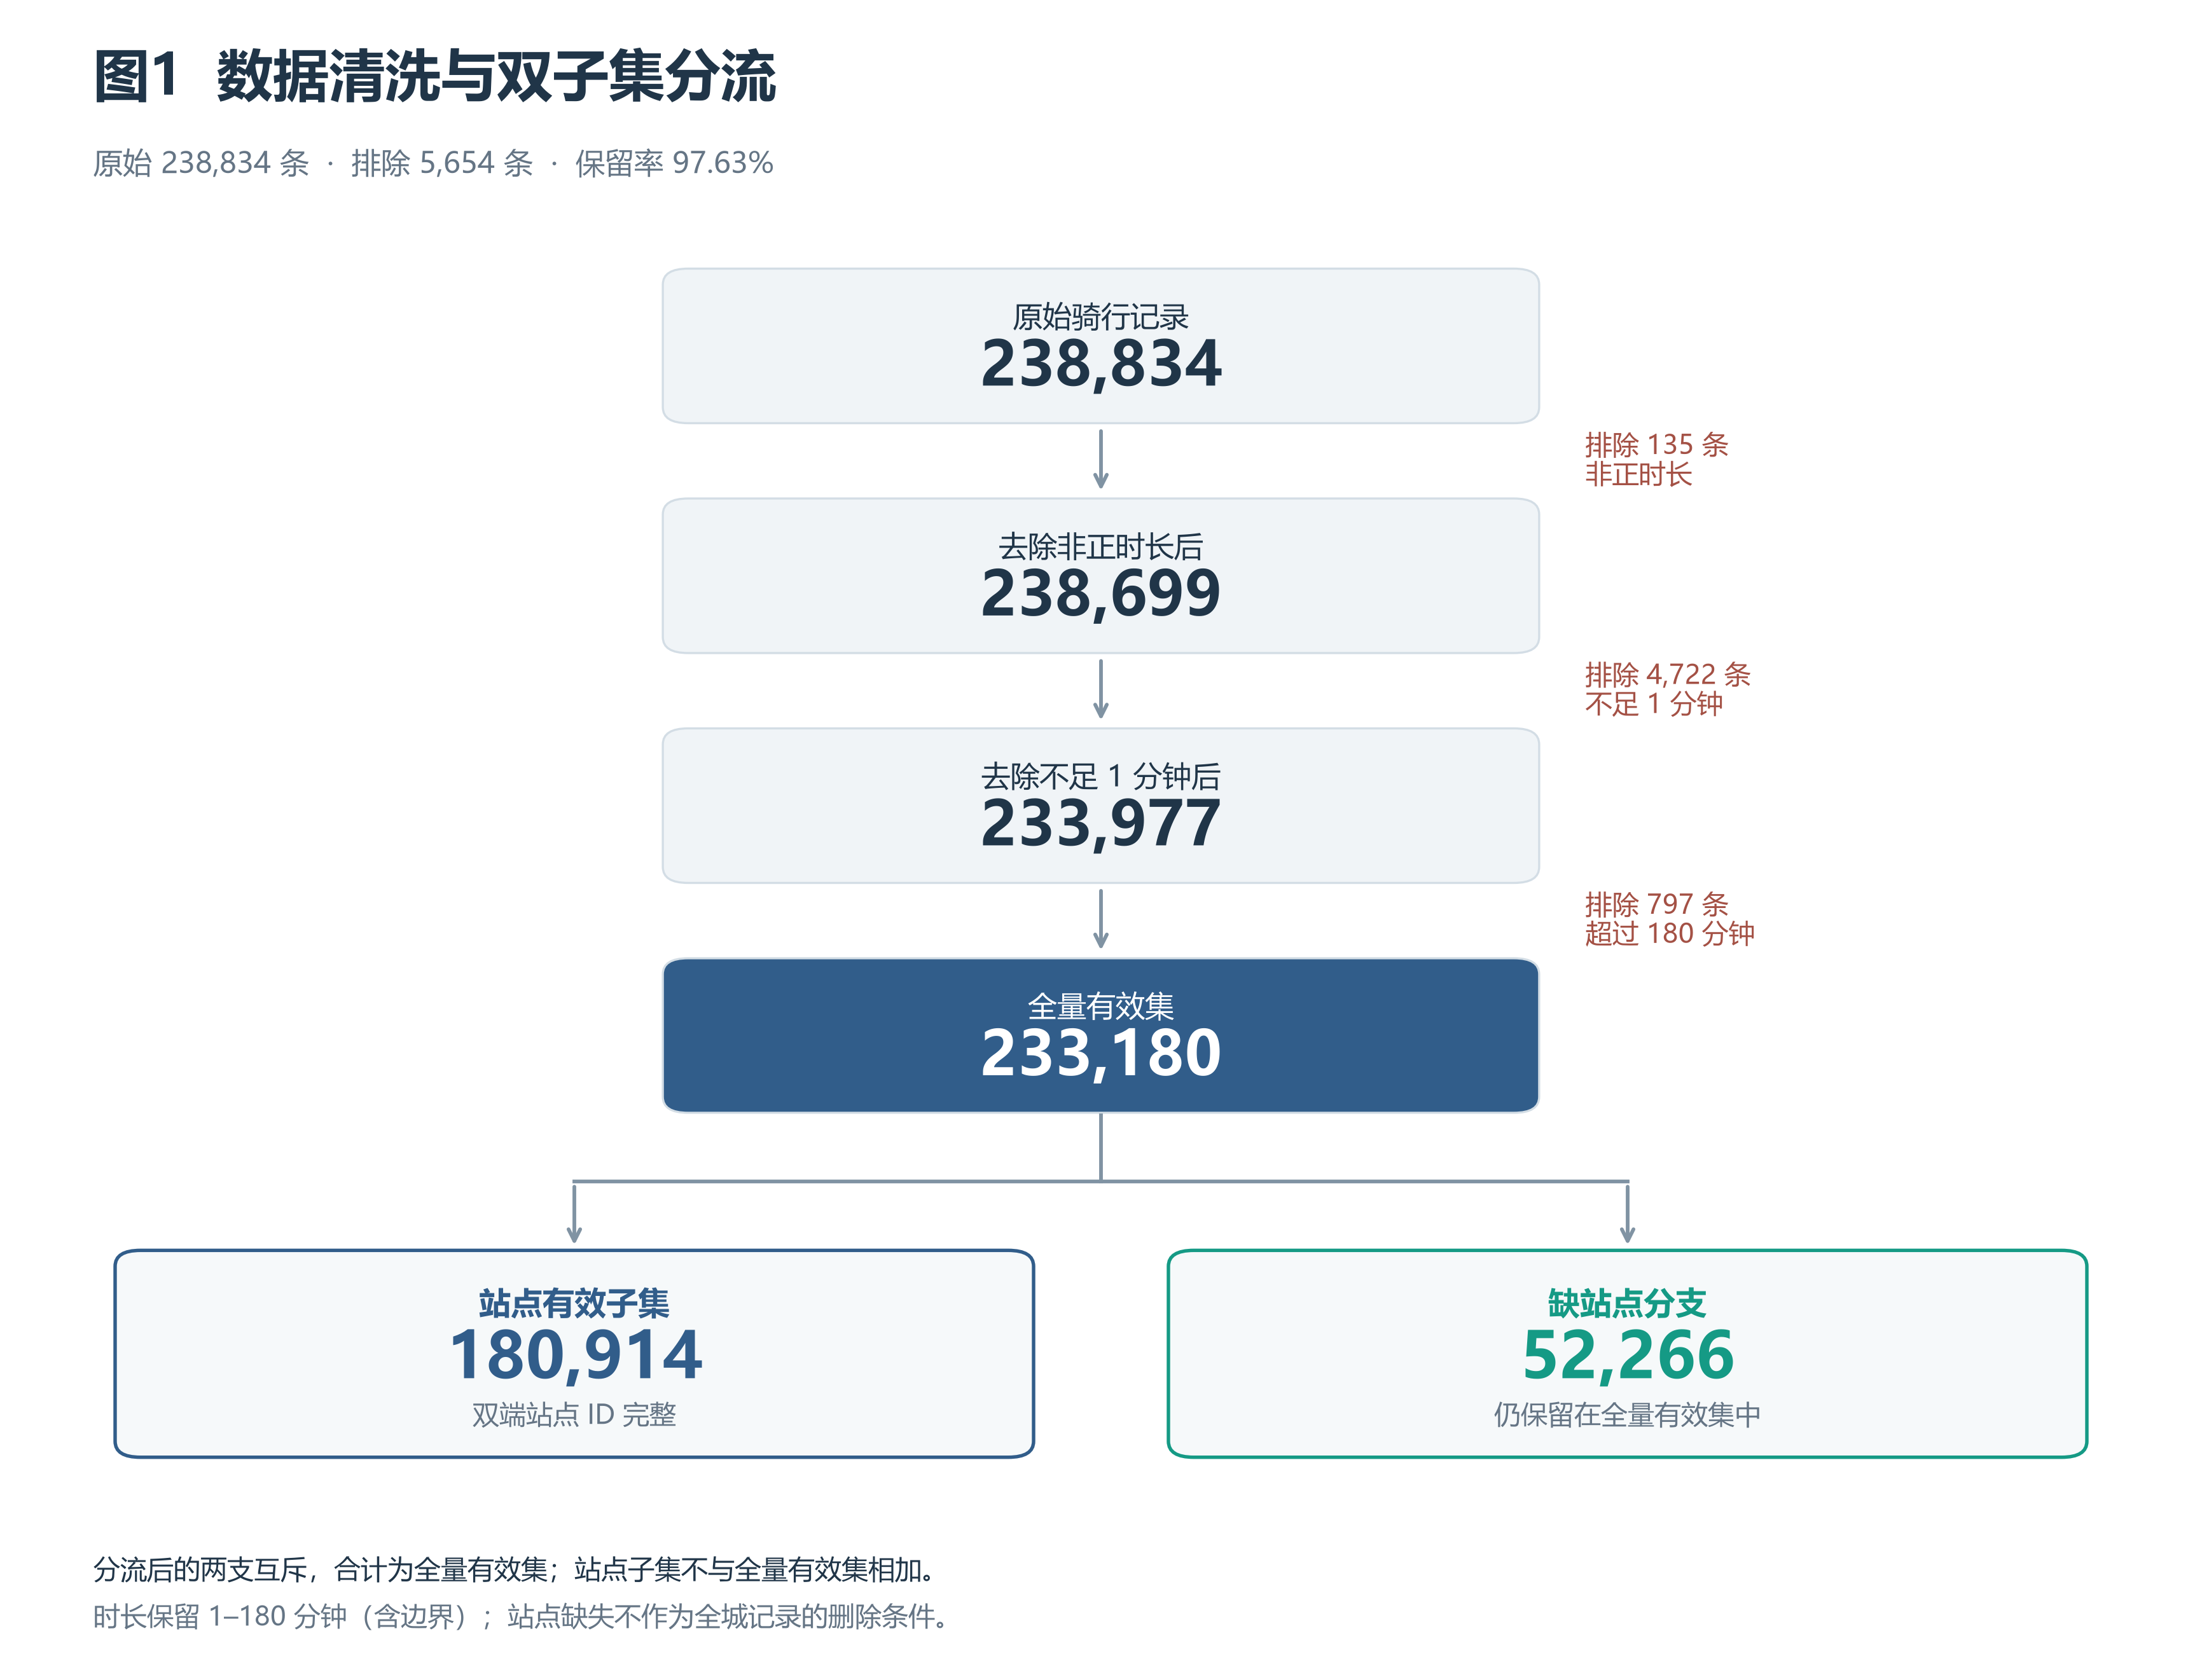

In [9]:
figure_paths = {}
figure = plot_cleaning_funnel(audit.funnel, clean, station, rules)
figure_paths["图1"] = save_figure(figure, "fig01_cleaning_funnel.png")
plt.close(figure)
display(DisplayImage(filename=str(figure_paths["图1"]), width=1100))

In [10]:
full_funnel = audit.funnel.loc[audit.funnel.scope.eq("full")]
display(full_funnel.rename(columns={
    "scope": "范围", "stage": "步骤", "removed_rows": "本步新增排除", "remaining_rows": "剩余记录数",
}))
display(Markdown(
    f"- 从 **{len(raw):,}** 条原始记录中排除 **{len(raw) - len(clean):,}** 条，"
    f"保留 **{len(clean):,}** 条，保留率 **{len(clean) / len(raw):.2%}**。\n"
    f"- 站点子集包含 **{len(station):,}** 条，占全量有效集 **{len(station) / len(clean):.2%}**；"
    f"其余 **{len(clean) - len(station):,}** 条仍保留用于全城时间等分析。\n"
    "- 站点缺失没有直接作为全量删除条件，避免把缺站点电单车记录整体剔除。"
))

,范围,步骤,本步新增排除,剩余记录数
0,full,raw,0,238834
1,full,missing_ride_id,0,238834
2,full,duplicate_ride_id,0,238834
3,full,invalid_timestamp,0,238834
4,full,outside_analysis_month,0,238834
5,full,unsupported_rideable_type,0,238834
6,full,unsupported_member_type,0,238834
7,full,nonpositive_duration,135,238699
8,full,short_duration,4722,233977
9,full,long_duration,797,233180


- 从 **238,834** 条原始记录中排除 **5,654** 条，保留 **233,180** 条，保留率 **97.63%**。
- 站点子集包含 **180,914** 条，占全量有效集 **77.59%**；其余 **52,266** 条仍保留用于全城时间等分析。
- 站点缺失没有直接作为全量删除条件，避免把缺站点电单车记录整体剔除。

## 6. 图2：车型、用户类型的时长与距离分布

箱体为 Q1–Q3，箱内线为中位数，须按 1.5×IQR 延伸。为便于比较典型分布，离群点不绘出，但全部有效观测仍参与分位数计算。距离使用可计算直线距离的子样本，各组分别标注样本量。

In [11]:
statistics, structure = build_summary_tables(clean)
statistics.to_csv(TABLE_DIR / "basic_eda_summary.csv", index=False, encoding="utf-8-sig", float_format="%.6f")
structure.to_csv(TABLE_DIR / "trip_structure_summary.csv", index=False, encoding="utf-8-sig", float_format="%.6f")
display(statistics[["group_label", "metric", "n_valid", "mean", "median", "q25", "q75"]].rename(columns={
    "group_label": "群体", "metric": "指标", "n_valid": "有效样本量", "mean": "均值",
    "median": "中位数", "q25": "Q1", "q75": "Q3",
}).round(3))

,群体,指标,有效样本量,均值,中位数,Q1,Q3
0,经典车,duration_min,114490,13.151,9.133,5.517,15.117
1,经典车,dist_km,114490,1.614,1.340,0.816,2.101
2,电单车,duration_min,118690,11.739,8.667,5.233,13.983
3,电单车,dist_km,118690,1.981,1.614,0.930,2.635
4,会员,duration_min,172990,11.081,8.350,5.033,13.533
5,会员,dist_km,172990,1.760,1.409,0.856,2.339
6,散客,duration_min,60190,16.318,10.667,6.633,17.883
7,散客,dist_km,60190,1.916,1.595,0.996,2.469


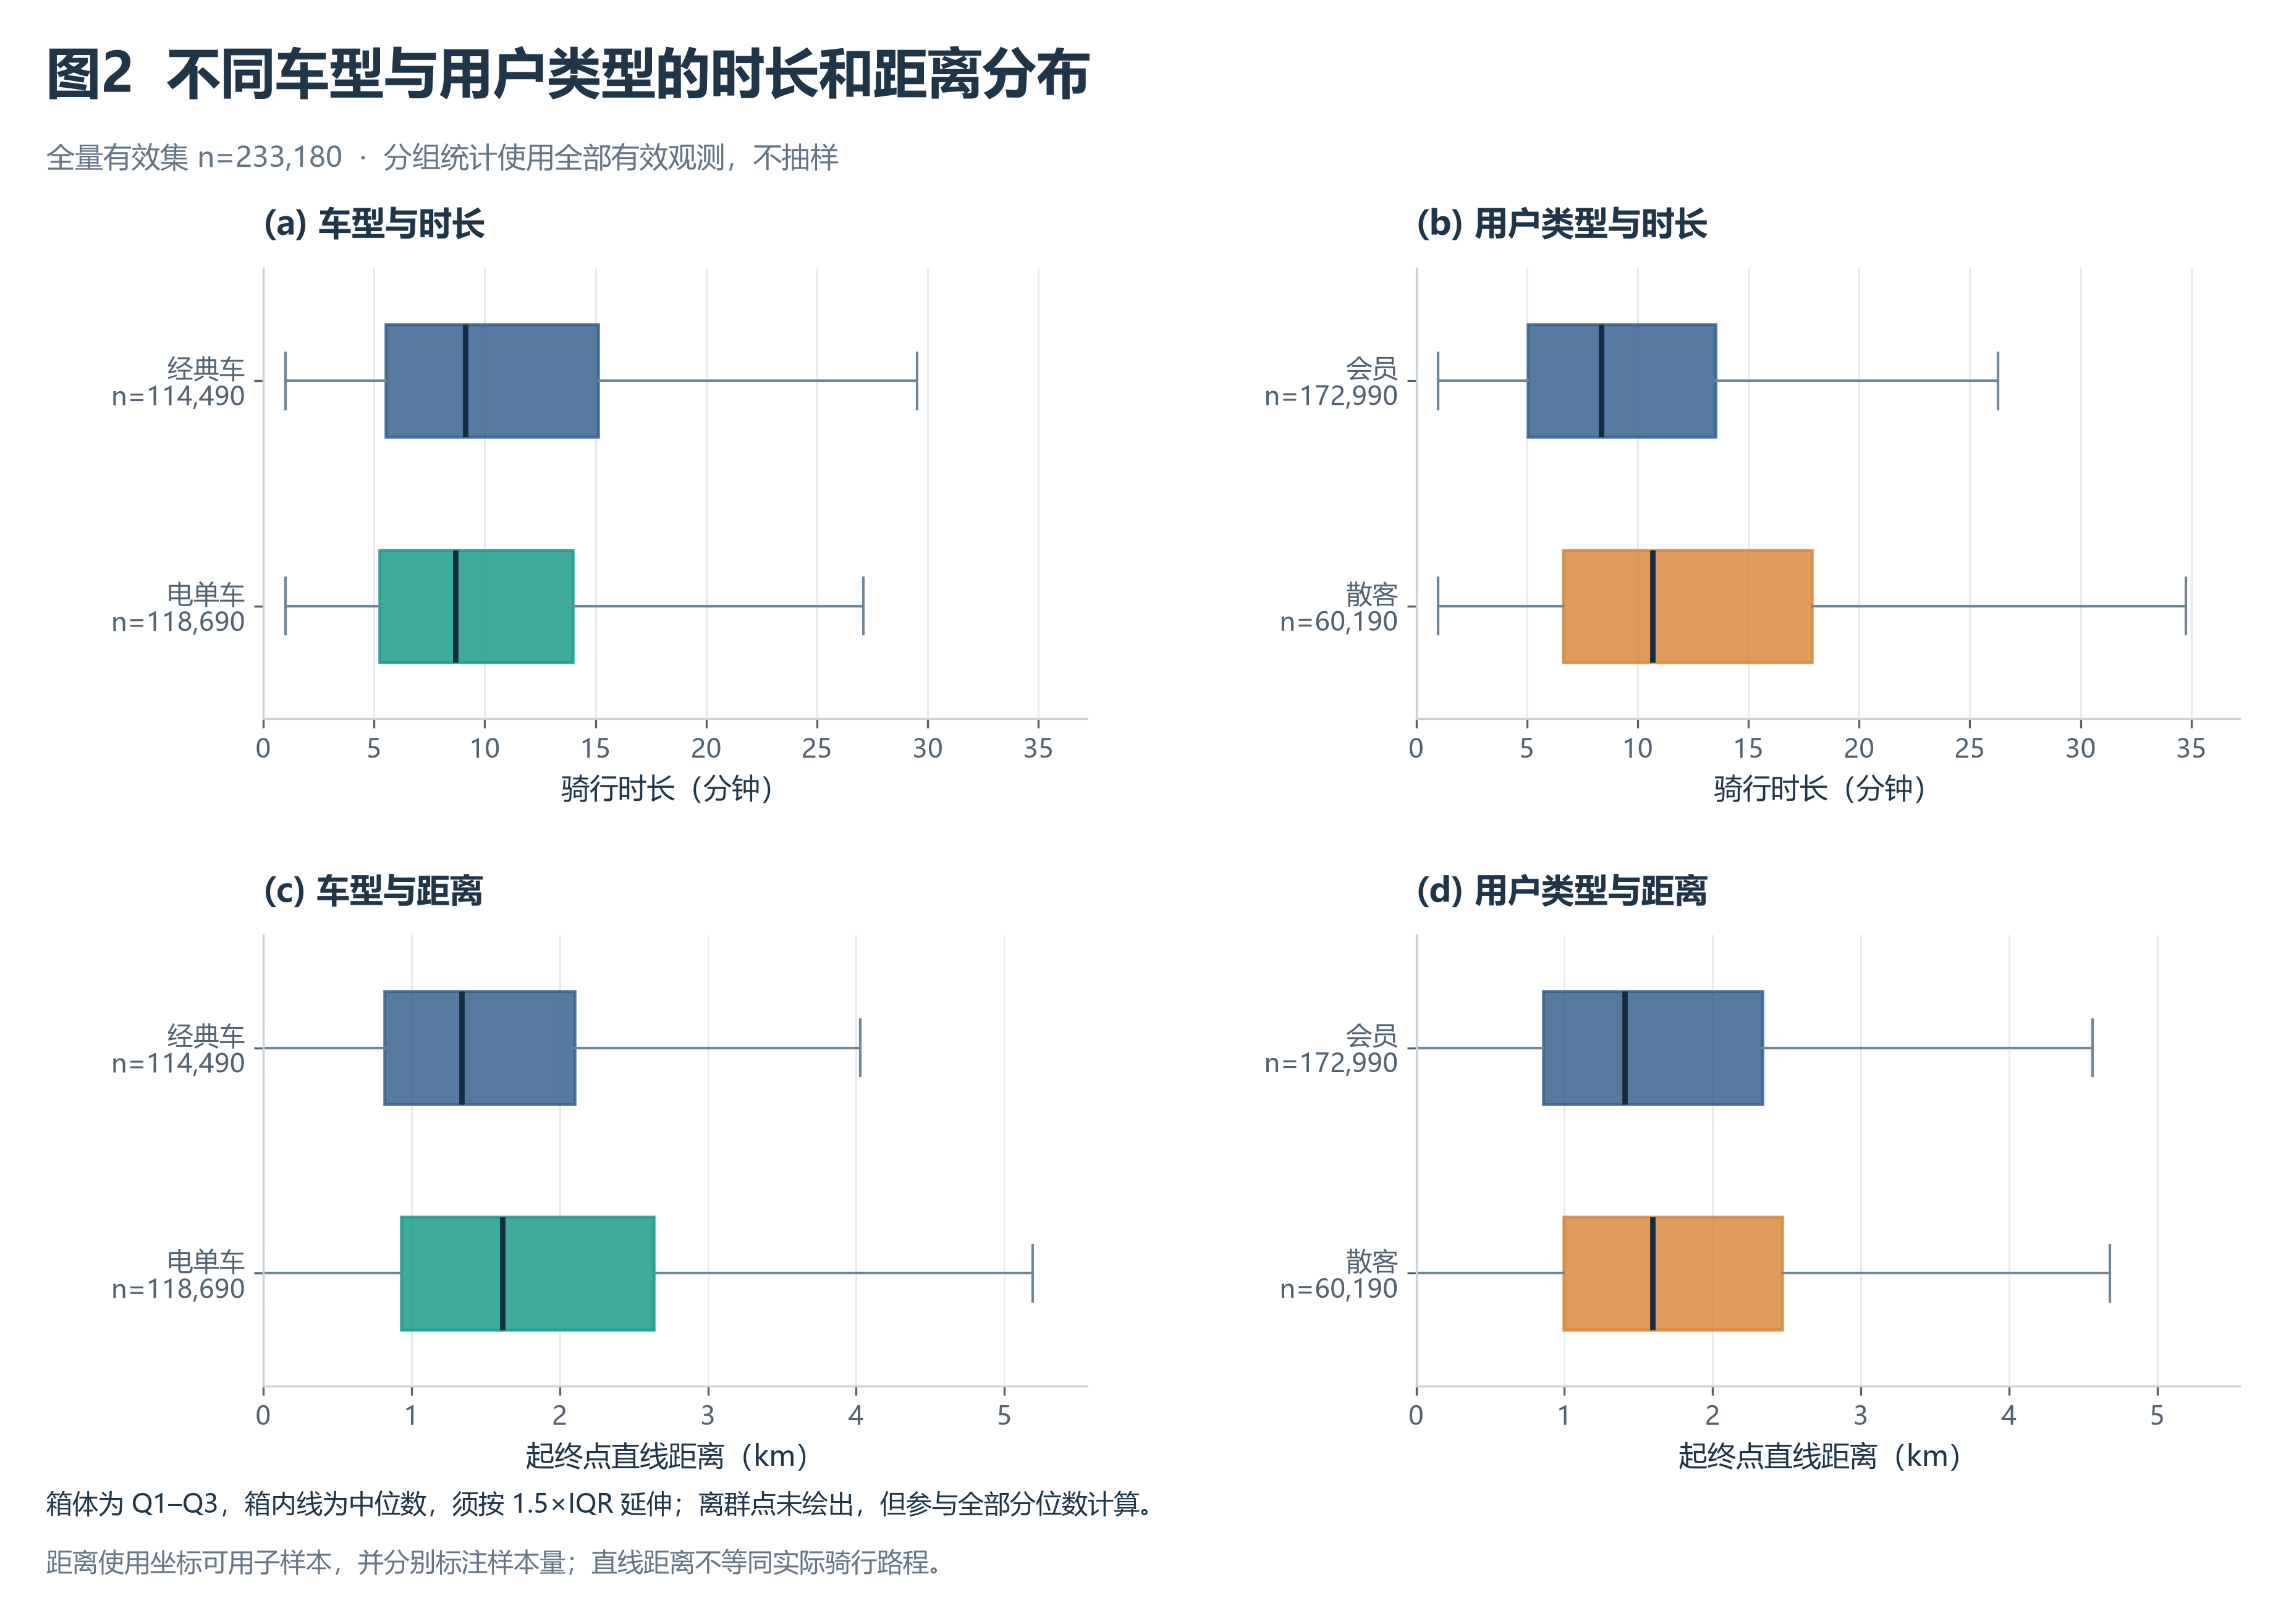

In [12]:
figure = plot_duration_distance(clean)
figure_paths["图2"] = save_figure(figure, "fig02_duration_distance_distribution.png")
plt.close(figure)
display(DisplayImage(filename=str(figure_paths["图2"]), width=1100))

In [13]:
indexed_statistics = statistics.set_index(["dimension", "group", "metric"])
classic_minutes = float(indexed_statistics.loc[("rideable_type", "classic_bike", "duration_min"), "median"])
electric_minutes = float(indexed_statistics.loc[("rideable_type", "electric_bike", "duration_min"), "median"])
classic_distance = float(indexed_statistics.loc[("rideable_type", "classic_bike", "dist_km"), "median"])
electric_distance = float(indexed_statistics.loc[("rideable_type", "electric_bike", "dist_km"), "median"])
member_minutes = float(indexed_statistics.loc[("member_casual", "member", "duration_min"), "median"])
casual_minutes = float(indexed_statistics.loc[("member_casual", "casual", "duration_min"), "median"])

display(Markdown(
    f"- 经典车与电单车的骑行时长中位数分别为 **{classic_minutes:.2f}、{electric_minutes:.2f} 分钟**；"
    f"直线距离中位数分别为 **{classic_distance:.2f}、{electric_distance:.2f} km**。\n"
    f"- 会员与散客的时长中位数分别为 **{member_minutes:.2f}、{casual_minutes:.2f} 分钟**，"
    "群体差异应结合出发时段、地区及车型进一步分析。\n"
    "- 这些是样本中的关联，不能据此推断车型或会员身份造成差异，也不能把直线距离除以时长解释为真实骑行速度。"
))

- 经典车与电单车的骑行时长中位数分别为 **9.13、8.67 分钟**；直线距离中位数分别为 **1.34、1.61 km**。
- 会员与散客的时长中位数分别为 **8.35、10.67 分钟**，群体差异应结合出发时段、地区及车型进一步分析。
- 这些是样本中的关联，不能据此推断车型或会员身份造成差异，也不能把直线距离除以时长解释为真实骑行速度。

## 7. 图3：站点记录与环线骑行结构

“双端站点完整”“疑似无桩电单车”“其他缺站点”按已导出的标记划分，互斥且覆盖全量有效集。“疑似无桩”只是电单车且至少一端站点 ID 缺失的代理标记。

环线占比另以可判定的站点子集为分母，缺站点记录保留为未知。异站骑行不直接等于通勤，同站环线也不能仅凭订单数据确定出行目的。

,统计维度,类别,记录数,统计分母,占比（%）
0,station_structure,双端站点完整,180914,233180,77.59
1,station_structure,疑似无桩电单车,52266,233180,22.41
2,station_structure,其他缺站点,0,233180,0.00
3,loop_availability,环线可判定,180914,233180,77.59
4,loop_availability,环线未知,52266,233180,22.41
5,loop_structure,异站骑行,176303,180914,97.45
6,loop_structure,同站环线,4611,180914,2.55


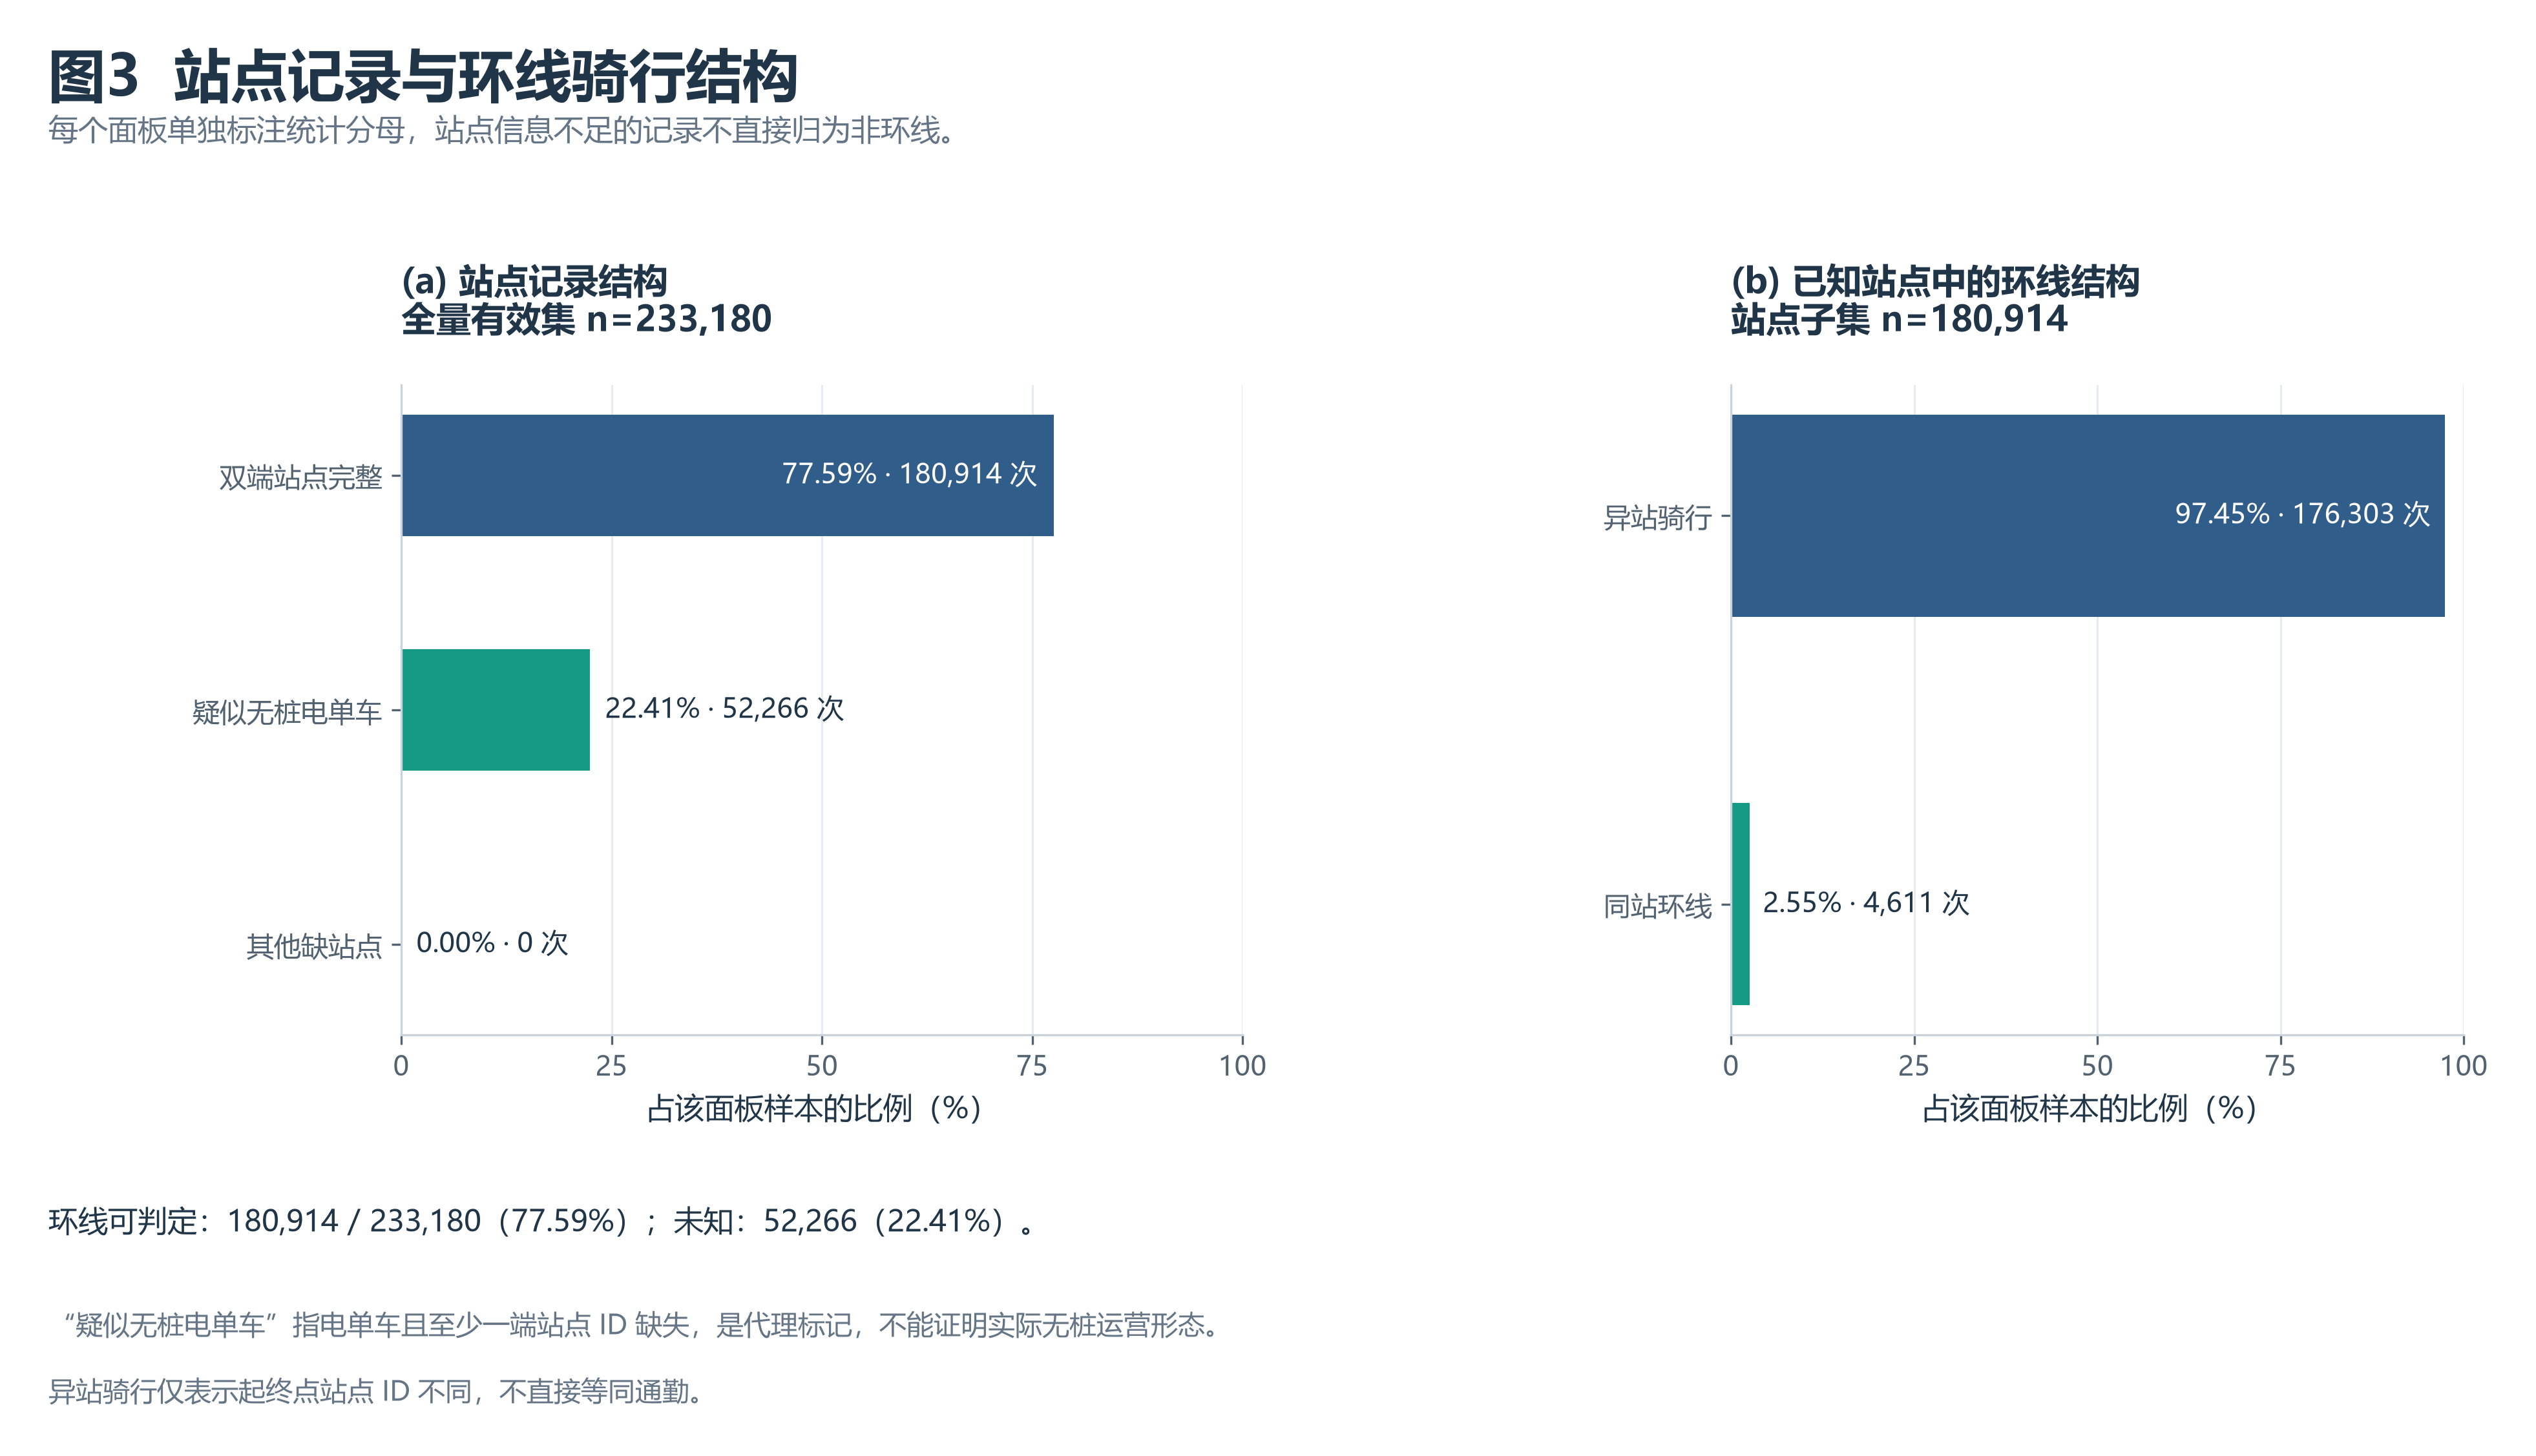

In [14]:
display(structure[["dimension", "label", "count", "denominator", "percent"]].rename(columns={
    "dimension": "统计维度", "label": "类别", "count": "记录数",
    "denominator": "统计分母", "percent": "占比（%）",
}).round({"占比（%）": 2}))
figure = plot_trip_structure(clean, structure)
figure_paths["图3"] = save_figure(figure, "fig03_trip_structure.png")
plt.close(figure)
display(DisplayImage(filename=str(figure_paths["图3"]), width=1100))

In [15]:
structure_by_category = structure.set_index("category")
known_count = int(structure_by_category.loc["known", "count"])
unknown_count = int(structure_by_category.loc["unknown", "count"])
proxy_count = int(structure_by_category.loc["dockless_ebike_proxy", "count"])
loop_count = int(structure_by_category.loc["loop_trip", "count"])
loop_share = float(structure_by_category.loc["loop_trip", "percent"])
display(Markdown(
    f"- 双端站点完整 **{known_count:,}** 条，占全量有效集 **{known_count / len(clean):.2%}**；"
    f"疑似无桩电单车代理记录为 **{proxy_count:,}** 条。\n"
    f"- 同站环线 **{loop_count:,}** 条，占 **{known_count:,}** 条站点有效记录的 **{loop_share:.2f}%**。\n"
    f"- 另有 **{unknown_count:,}** 条记录的环线状态未知，占全量有效集 **{unknown_count / len(clean):.2%}**，"
    "未直接归入非环线。"
))

- 双端站点完整 **180,914** 条，占全量有效集 **77.59%**；疑似无桩电单车代理记录为 **52,266** 条。
- 同站环线 **4,611** 条，占 **180,914** 条站点有效记录的 **2.55%**。
- 另有 **52,266** 条记录的环线状态未知，占全量有效集 **22.41%**，未直接归入非环线。

## 8. 数据接口、局限与复现检查

原始 13 列保留字段名，新增 8 列供后续模块使用。CSV 本身不保存类型，组员应调用 `read_clean_data()` 恢复字符串 ID、datetime 和可缺失布尔值；不要把字符串 `"False"` 直接转成 `bool`。

- 陈宇涵使用全量有效集开展全城时间分析，使用站点子集建立站点需求数据。
- 康炜奕使用站点子集统计站点、OD 与失衡；分析疑似无桩电单车热点时，应从全量有效集中取对应记录，并另检查坐标是否有效。
- 本数据仅覆盖一个月份，没有天气、节假日专门标记和实时库存。不能由订单净流量直接确定真实库存，也不能仅凭超长时长确认丢车。

In [16]:
field_descriptions = {
    "duration_min": "完整起止时间之差，单位分钟",
    "dist_km": "Haversine 直线距离，单位 km；不可计算时缺失",
    "hour": "出发小时，0–23",
    "weekday": "出发星期，周一为 0、周日为 6",
    "is_weekend": "星期序号 >= 5，不等同于节假日",
    "has_station_info": "起终点站点 ID 均已知",
    "is_dockless_ebike": "电单车且至少一端站点 ID 缺失的代理标记",
    "is_loop_trip": "已知站点 ID 是否相同；站点不足时为未知",
}
display(pd.DataFrame([
    {"字段": column, "实际类型": str(clean[column].dtype), "含义": description}
    for column, description in field_descriptions.items()
]))

,字段,实际类型,含义
0,duration_min,Float64,完整起止时间之差，单位分钟
1,dist_km,Float64,Haversine 直线距离，单位 km；不可计算时缺失
2,hour,int8,出发小时，0–23
3,weekday,int8,出发星期，周一为 0、周日为 6
4,is_weekend,boolean,星期序号 >= 5，不等同于节假日
5,has_station_info,boolean,起终点站点 ID 均已知
6,is_dockless_ebike,boolean,电单车且至少一端站点 ID 缺失的代理标记
7,is_loop_trip,boolean,已知站点 ID 是否相同；站点不足时为未知


In [17]:
with RAW_DATA_FILE.open("rb") as stream:
    final_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()
checks = {
    "原始文件未被改动": original_sha256 == final_sha256,
    "订单 ID 非空且唯一": bool(clean.ride_id.notna().all() and clean.ride_id.is_unique),
    "导出行数与审查结果一致": len(clean) == audit.summary["clean_trips"] and len(station) == audit.summary["station_trips"],
    "站点子集与全量对应记录一致": clean.loc[clean.has_station_info].reset_index(drop=True).equals(station),
    "时长在含边界阈值内": bool(clean.duration_min.between(rules.duration_min_inclusive, rules.duration_max_inclusive).all()),
    "环线未知与站点信息不足对应": bool(clean.is_loop_trip.isna().eq(~clean.has_station_info).all()),
    "已知距离非负且有限": bool((np.isfinite(clean.dist_km.dropna()) & clean.dist_km.dropna().ge(0)).all()),
}
for dimension, table in structure.groupby("dimension"):
    denominator = int(table.denominator.iloc[0])
    checks[f"{dimension} 分类计数守恒"] = int(table["count"].sum()) == denominator
for name, path in figure_paths.items():
    with PillowImage.open(path) as image:
        dpi = image.info.get("dpi", (0, 0))
        checks[f"{name}为300 DPI PNG"] = image.format == "PNG" and all(abs(value - 300) < 0.01 for value in dpi)
failed = [name for name, passed in checks.items() if not passed]
assert not failed, failed
display(pd.DataFrame({"检查项目": list(checks), "结果": ["通过" if passed else "失败" for passed in checks.values()]}))

,检查项目,结果
0,原始文件未被改动,通过
1,订单 ID 非空且唯一,通过
2,导出行数与审查结果一致,通过
3,站点子集与全量对应记录一致,通过
4,时长在含边界阈值内,通过
5,环线未知与站点信息不足对应,通过
6,已知距离非负且有限,通过
7,loop_availability 分类计数守恒,通过
8,loop_structure 分类计数守恒,通过
9,station_structure 分类计数守恒,通过


In [18]:
artifacts = [
    *outputs.values(), *figure_paths.values(),
    TABLE_DIR / "data_quality_summary.md", TABLE_DIR / "basic_eda_summary.csv",
    TABLE_DIR / "trip_structure_summary.csv",
]
display(pd.DataFrame([
    {"本地输出文件": path.relative_to(ROOT).as_posix(), "大小（MiB）": round(path.stat().st_size / 1024**2, 3)}
    for path in artifacts
]))
print("运行完成：两份 CSV、图1–3和相关审查/统计结果已重新生成，所有复现检查通过。")

,本地输出文件,大小（MiB）
0,data/processed/clean_trips.csv,51.828
1,data/processed/station_trips.csv,42.542
2,reports/figures/fig01_cleaning_funnel.png,0.324
3,reports/figures/fig02_duration_distance_distri...,0.333
4,reports/figures/fig03_trip_structure.png,0.318
5,reports/tables/data_quality_summary.md,0.008
6,reports/tables/basic_eda_summary.csv,0.001
7,reports/tables/trip_structure_summary.csv,0.001


运行完成：两份 CSV、图1–3和相关审查/统计结果已重新生成，所有复现检查通过。


## 9. 本部分结论

本 Notebook 已从原始记录复现数据质量审查、统一清洗规则、两个数据子集和三张基础探索图。清洗阶段采用可计数、可追溯的规则；群体比较同时报告中位数和分布；结构比较明确统计分母并保留未知状态。

上述数值结论均由运行中的数据计算。后续时间预测与空间调度应沿用相同数据接口，并在解释结果时保留本节列出的局限。